<div style="text-align:center;background:#365e82;color:white;padding:24px;">
<h1 style="color:white;font-weight:700;">Selección de k y entrenamiento de K-NN</h1>
<h3 style="color:white;font-weight:400;">Clasificación de variedades de frijol · Dry Bean</h3>
<p style="color:white;">Elaborado por: </p>
</div>

<a id="indice"></a>
<div style="text-align:left;background:white;color:black;padding:20px;">
<h2 style="color:black;font-weight:700;">ÍNDICE</h2>
<ul style="line-height:1.85;">
<li><a href="#presentacion">Presentación y preparación</a></li>
<li><a href="#herramientas">1. Importar las herramientas</a></li>
<li><a href="#datos">2. Abrir el conjunto de datos</a></li>
<li><a href="#variables">3. Separar las medidas y la variedad</a></li>
<li><a href="#division">4. Separar entrenamiento y prueba</a></li>
<li><a href="#valores-k">5. Preparar los valores de k</a></li>
<li><a href="#comparacion">6. Comparar y seleccionar k</a></li>
<li><a href="#modelo-final">7. Entrenar el modelo final</a></li>
<li><a href="#grafica">8. Representar la comparación</a></li>
<li><a href="#referencias">Referencias</a></li>
</ul>
</div>

<a id="presentacion"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">Presentación y preparación</h2>

**Objetivo.** Preparar un modelo que identifique la variedad de un frijol a partir de sus 16 medidas. Se comparan los valores de `k` del 1 al 25 y se elige el que obtiene mayor exactitud media.

K-NN clasifica por semejanza: Busca los `k` ejemplos de entrenamiento más cercanos y elige la variedad con más votos. Por ejemplo, `k=5` significa consultar cinco vecinos.

**Archivos necesarios.** `datos_limpios1.csv`. Una fila representa un frijol; las medidas describen su tamaño y forma, y `Class` indica su variedad real.

**Cómo ejecutarlo.** Colocar el archivo .CSV y este cuaderno en la misma carpeta. Abrir JupyterLab con el entorno `ing-con`, selecciona su kernel de Python y ejecuta las celdas de arriba abajo con **Shift + Enter**.

Para escoger `k`, se utiliza una comparación interna dentro del 80 % de entrenamiento. El 20 % de prueba queda reservado para la evaluación final.

<a id="herramientas"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">1. Importar las herramientas</h2>

Una **biblioteca** reúne herramientas de programación ya hechas. `import` permite utilizarlas; `as` les asigna un nombre corto, como `pd` para pandas. Con `from ... import ...` se eligen herramientas específicas.

| Biblioteca | Función en este proyecto |
|---|---|
| pandas (`pd`) | Leer y organizar la tabla. |
| Matplotlib (`plt`) | Dibujar la gráfica. |
| scikit-learn (`sklearn`) | Separar datos, escalar medidas y preparar K-NN. |

Cada herramienta de scikit-learn se explica en el apartado donde se utiliza.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

<a id="datos"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">2. Abrir el conjunto de datos</h2>

`pd.read_csv()` lee el archivo CSV. El signo `=` guarda la tabla en una **variable**, es decir, un nombre que usaremos para acceder a su contenido: `datos`.

`datos.shape` muestra el tamaño como **(filas, columnas)**. `datos.head()` presenta las primeras cinco filas para revisar cómo está organizada la tabla.

Si el archivo contiene las 13 543 filas previstas en el proyecto, se espera un tamaño de **(13543, 17)**: 16 medidas y una columna de variedad.

In [8]:
datos = pd.read_csv("datos_limpios1.csv")

print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (13543, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


<a id="variables"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">3. Separar las medidas y la variedad</h2>

El programa necesita distinguir la información que usará para decidir y la respuesta correcta de cada ejemplo.

| Variable | Contenido |
|---|---|
| `X` | Las 16 medidas numéricas de cada frijol. |
| `y` | La variedad real, tomada de `Class`. |

`drop(columns=["Class"])` crea una tabla sin la columna de respuesta. La tabla original se conserva en `datos`.

Las instrucciones `if` revisan dos condiciones: que existan 16 medidas y que no haya filas repetidas. Si detectan un problema, `raise ValueError(...)` detiene la ejecución y muestra el mensaje indicado.

In [9]:
X = datos.drop(columns=["Class"])  # Las medidas, sin la respuesta.
y = datos["Class"]                 # La variedad real del frijol.

if X.shape[1] != 16:
    raise ValueError("El CSV debe tener 16 medidas y la columna Class.")

if datos.duplicated().any():
    raise ValueError("El CSV contiene filas repetidas. Revisa su limpieza.")

<a id="division"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">4. Separar entrenamiento y prueba</h2>

El **entrenamiento** contiene los ejemplos con los que se prepara el modelo. La **prueba** queda apartada para comprobar posteriormente cómo clasifica casos que no utilizó para prepararse.

`train_test_split()` divide las medidas y sus respuestas juntas, conservando la correspondencia entre cada frijol y su variedad.

| Opción | Significado |
|---|---|
| `test_size=0.20` | Reserva el 20 % para prueba; el resto es entrenamiento. |
| `random_state=42` | Repite el reparto si se conservan los mismos datos y su orden. |
| `stratify=y` | Mantiene proporciones parecidas de las variedades en ambos grupos. |

Los nombres `X_train` y `y_train` corresponden al entrenamiento; `X_test` y `y_test`, a la prueba. Con 13 543 filas, se esperan **10 834 de entrenamiento y 2 709 de prueba**.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,    # Reserva el 20 % para la prueba final.
    random_state=42,  # Repite el reparto con los mismos datos y orden.
    stratify=y        # Mantiene proporciones parecidas de las variedades.
)

print("Frijoles para entrenar:", len(X_train))
print("Frijoles para la prueba final:", len(X_test))

Frijoles para entrenar: 10834
Frijoles para la prueba final: 2709


<a id="valores-k"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">5. Preparar los valores de k</h2>

En Python usaremos una **lista** como vector de candidatos. `list(range(1, 26))` genera los números del 1 al 25; el límite final, 26, queda excluido.

`StratifiedKFold` organiza el entrenamiento en cinco partes con proporciones parecidas de las variedades. Para cada `k`, se ajusta el modelo con cuatro partes y se compara con la restante. Esta se va rotando hasta obtener cinco resultados. Todos los candidatos utilizan los mismos repartos.

**Las cinco partes no son cinco vecinos.** Las partes organizan la comparación; `k` indica cuántos vecinos votan.

| Variable | Para qué se prepara |
|---|---|
| `porcentajes = []` | Una lista vacía para guardar los resultados. |
| `mejor_k = 1` | El primer candidato de la lista. |
| `mejor_exactitud = -1` | Un valor inicial menor que cualquier exactitud válida; así, el primer resultado se guarda. |

In [11]:
valores_k = list(range(1, 26))  # Lista de números del 1 al 25.

comparacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

porcentajes = []       # Aquí guardaremos el resultado de cada k.
mejor_k = 1
mejor_exactitud = -1   # Así, el primer resultado será el ganador inicial.

<a id="comparacion"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">6. Comparar y seleccionar k</h2>

El ciclo `for k in valores_k:` significa: **para cada número de la lista, repite las instrucciones que están dentro**. La sangría —los espacios al inicio de las líneas— indica qué instrucciones pertenecen al ciclo.

En cada vuelta, `Pipeline` une dos pasos: `StandardScaler` pone las medidas en escalas comparables y `KNeighborsClassifier(n_neighbors=k)` prepara K-NN con el número de vecinos actual. El escalador se ajusta dentro de cada comparación con los datos que corresponden al entrenamiento.

`cross_val_score()` devuelve las cinco exactitudes del candidato. **Exactitud** significa aciertos divididos entre casos comparados. El conjunto de prueba final no participa en esta selección.

| Instrucción | Qué hace |
|---|---|
| `resultados.mean()` | Calcula el promedio de las cinco exactitudes. |
| `porcentajes.append(...)` | Añade un resultado a la lista; multiplicar por 100 lo expresa como porcentaje. |
| `round(..., 2)` | Redondea únicamente el valor mostrado a dos decimales. |
| `if exactitud > mejor_exactitud:` | Guarda el nuevo ganador solo cuando mejora al anterior. |

`error_score="raise"` permite que se muestre un error si alguna comparación no puede realizarse.

In [12]:
for k in valores_k:
    candidato = Pipeline([
        ("escalador", StandardScaler()),  # Hace comparables las medidas.
        ("knn", KNeighborsClassifier(n_neighbors=k))  # Usa k vecinos.
    ])

    resultados = cross_val_score(
        candidato,
        X_train,
        y_train,
        cv=comparacion,
        scoring="accuracy",  # Mide la proporción de aciertos.
        error_score="raise"
    )

    exactitud = resultados.mean()       # Promedio de las cinco comparaciones.
    porcentajes.append(exactitud * 100) # Guarda el resultado como porcentaje.

    print("k =", k, "| Exactitud media (%):", round(exactitud * 100, 2))

    if exactitud > mejor_exactitud:
        mejor_exactitud = exactitud
        mejor_k = k

k = 1 | Exactitud media (%): 90.43
k = 2 | Exactitud media (%): 90.15
k = 3 | Exactitud media (%): 91.67
k = 4 | Exactitud media (%): 91.88
k = 5 | Exactitud media (%): 92.09
k = 6 | Exactitud media (%): 92.34
k = 7 | Exactitud media (%): 92.32
k = 8 | Exactitud media (%): 92.31
k = 9 | Exactitud media (%): 92.39
k = 10 | Exactitud media (%): 92.35
k = 11 | Exactitud media (%): 92.38
k = 12 | Exactitud media (%): 92.39
k = 13 | Exactitud media (%): 92.34
k = 14 | Exactitud media (%): 92.34
k = 15 | Exactitud media (%): 92.44
k = 16 | Exactitud media (%): 92.43
k = 17 | Exactitud media (%): 92.38
k = 18 | Exactitud media (%): 92.39
k = 19 | Exactitud media (%): 92.48
k = 20 | Exactitud media (%): 92.47
k = 21 | Exactitud media (%): 92.48
k = 22 | Exactitud media (%): 92.38
k = 23 | Exactitud media (%): 92.44
k = 24 | Exactitud media (%): 92.39
k = 25 | Exactitud media (%): 92.38


### Lectura de los resultados

En cada vuelta se imprime el valor de `k` y su exactitud media. Al terminar, `mejor_k` contiene el ganador. Si hay un empate exacto, queda el menor `k`, porque la lista se recorre de menor a mayor.

La selección utiliza los promedios sin redondear. `tabla_k` reúne los 25 candidatos y sus porcentajes para consultarlos con facilidad. El ganador es el mejor **entre estos candidatos y según este criterio**, no un valor óptimo para cualquier conjunto de datos.

In [13]:
print("Mejor k:", mejor_k)
print("Exactitud media (%):", round(mejor_exactitud * 100, 2))

tabla_k = pd.DataFrame({
    "k": valores_k,
    "exactitud_porcentaje": porcentajes
})

tabla_k

Mejor k: 19
Exactitud media (%): 92.48


,k,exactitud_porcentaje
0,1,90.428351
1,2,90.151432
2,3,91.674466
3,4,91.877478
4,5,92.089804
5,6,92.339022
6,7,92.320555
7,8,92.311304
8,9,92.394398
9,10,92.348243


<a id="modelo-final"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">7. Entrenar el modelo final</h2>

Durante la comparación se utilizaron modelos temporales. Ahora se crea `modelo` con el `mejor_k` seleccionado y se prepara con **todo el 80 % de entrenamiento**.

`modelo.fit(X_train, y_train)` ajusta el escalador y prepara K-NN con las medidas y sus variedades reales. En K-NN, esta preparación conserva los ejemplos que consultará cuando se le pida clasificar un frijol.

El conjunto de prueba continúa apartado para la evaluación posterior.

In [14]:
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=mejor_k))
])

modelo.fit(X_train, y_train)

print("Modelo final preparado con k =", mejor_k)

Modelo final preparado con k = 19


<a id="grafica"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">8. Representar la comparación</h2>

La gráfica permite observar cómo cambia el resultado al utilizar distintas cantidades de vecinos.

| Elemento | Qué representa |
|---|---|
| Eje horizontal | Los valores de `k`, del 1 al 25. |
| Eje vertical | La exactitud media de las comparaciones internas, en porcentaje. |
| Cada punto | El resultado de un candidato. |

Los puntos más altos corresponden a los mayores promedios. La exactitud de esta gráfica se utiliza para seleccionar `k`; la evaluación final se obtendrá con los datos de prueba.

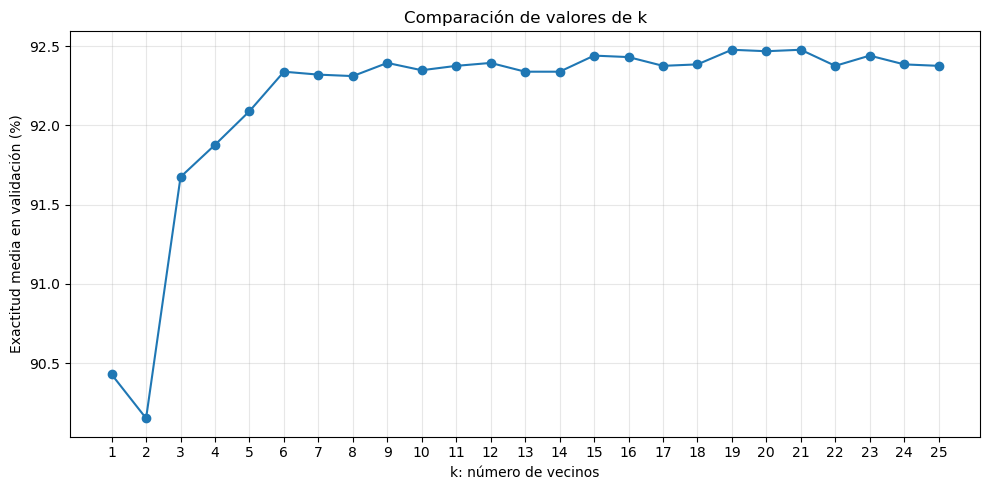

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(valores_k, porcentajes, marker="o")
plt.xlabel("k: número de vecinos")
plt.ylabel("Exactitud media en validación (%)")
plt.title("Comparación de valores de k")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<a id="referencias"></a>
<h2 style="text-align:left;background:#e7f4fe;color:#111111;padding:20px;font-weight:700;">Referencias</h2>

